In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display plots inside notebook
%matplotlib inline
df = pd.read_csv("../data/train.csv")
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [4]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])
df.columns
df.info()
df.isnull().sum()
df.describe()
print("Duplicate Rows:", df.duplicated().sum())


Rows : 159571
Columns : 8
<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   id             159571 non-null  str  
 1   comment_text   159571 non-null  str  
 2   toxic          159571 non-null  int64
 3   severe_toxic   159571 non-null  int64
 4   obscene        159571 non-null  int64
 5   threat         159571 non-null  int64
 6   insult         159571 non-null  int64
 7   identity_hate  159571 non-null  int64
dtypes: int64(6), str(2)
memory usage: 72.2 MB
Duplicate Rows: 0


In [5]:
# Sum of each toxicity label
df.iloc[:, 2:].sum()

toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64

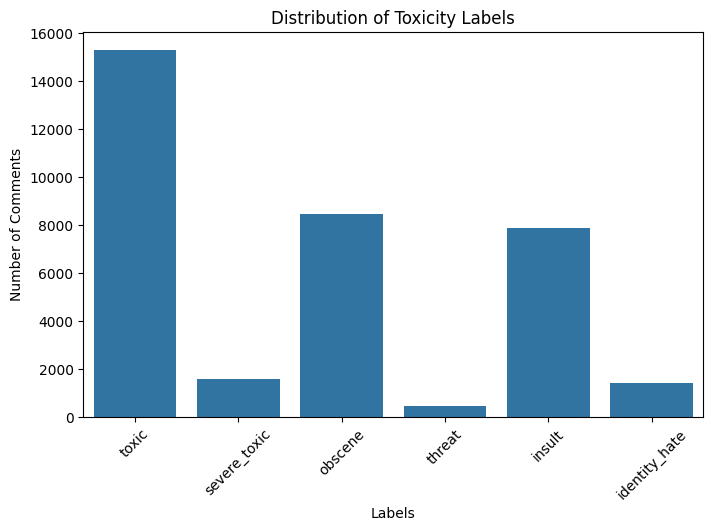

In [6]:
label_counts = df.iloc[:,2:].sum()

plt.figure(figsize=(8,5))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)

plt.title("Distribution of Toxicity Labels")
plt.xlabel("Labels")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)

plt.show()

In [8]:
df["comment_length"] = df["comment_text"].apply(len)

df["comment_length"].describe()

count    159571.000000
mean        394.073221
std         590.720282
min           6.000000
25%          96.000000
50%         205.000000
75%         435.000000
max        5000.000000
Name: comment_length, dtype: float64

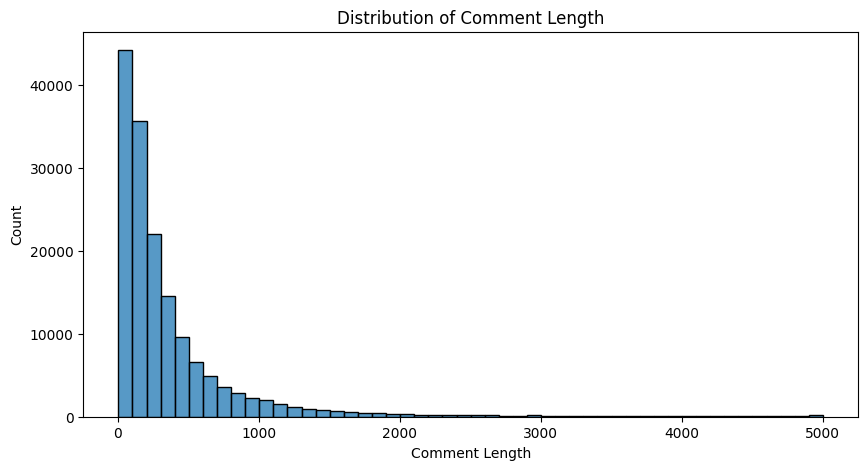

In [9]:
plt.figure(figsize=(10,5))

sns.histplot(df["comment_length"], bins=50)

plt.title("Distribution of Comment Length")
plt.xlabel("Comment Length")
plt.ylabel("Count")

plt.show()

In [10]:
df.loc[df["comment_length"].idxmax(), "comment_text"]

'ii CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARREST ME...SAN DIEGO CALIFORNIA, CHULA VISTA, FUCKING GET YOUR INFORMATION RIGHT FAGGOT SHITHEAD!!i CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARREST ME...SAN DIEGO CALIFORNIA, CHULA VISTA, FUCKING GET YOUR INFORMATION RIGHT FAGGOT SHITHEAD!!i CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARREST ME...SAN DIEGO CALIFORNIA, CHULA VISTA, FUCKING GET YOUR INFORMATION RIGHT FAGGOT SHITHEAD!!i CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARREST ME...SAN DIEGO CALIFORNIA, CHULA VISTA, FUCKING GET YOUR INFORMATION RIGHT FAGGOT SHITHEAD!!i CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARREST ME...SAN DIEGO CALIFORNIA, CHULA VISTA, FUCKING GET YOUR INFORMATION RIGHT FAGGOT SHITHEAD!!i CAN STILL POST WITH THIS COMPUTER...I SAID BLOCK ME, COME THE FUCK DOWN HERE AND ARRES

In [11]:
df.loc[df["comment_length"].idxmin(), "comment_text"]

'14:53,'

In [12]:
toxic_percentage = (df["toxic"].sum() / len(df)) * 100

print(f"Toxic Comments: {toxic_percentage:.2f}%")

Toxic Comments: 9.58%


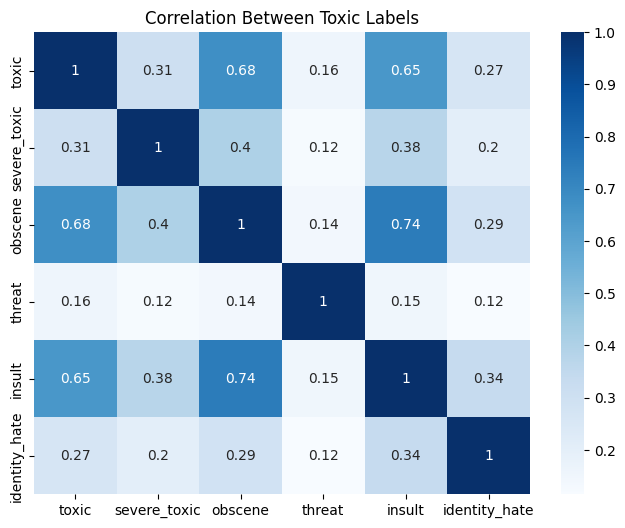

In [13]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df.iloc[:,2:8].corr(),
    annot=True,
    cmap="Blues"
)

plt.title("Correlation Between Toxic Labels")

plt.show()

In [14]:
df[df["toxic"] == 1][["comment_text"]].head(10)

,comment_text
6,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK
12,Hey... what is it..\n@ | talk .\nWhat is it......
16,"Bye! \n\nDon't look, come or think of comming ..."
42,You are gay or antisemmitian? \n\nArchangel WH...
43,"FUCK YOUR FILTHY MOTHER IN THE ASS, DRY!"
44,I'm Sorry \n\nI'm sorry I screwed around with ...
51,GET FUCKED UP. GET FUCKEEED UP. GOT A DRINK T...
55,Stupid peace of shit stop deleting my stuff as...
56,=Tony Sidaway is obviously a fistfuckee. He lo...
58,My Band Page's deletion. You thought I was gon...


In [15]:
df[df["toxic"] == 0][["comment_text"]].head(10)

,comment_text
0,Explanation\nWhy the edits made under my usern...
1,D'aww! He matches this background colour I'm s...
2,"Hey man, I'm really not trying to edit war. It..."
3,"""\nMore\nI can't make any real suggestions on ..."
4,"You, sir, are my hero. Any chance you remember..."
5,"""\n\nCongratulations from me as well, use the ..."
7,Your vandalism to the Matt Shirvington article...
8,Sorry if the word 'nonsense' was offensive to ...
9,alignment on this subject and which are contra...
10,"""\nFair use rationale for Image:Wonju.jpg\n\nT..."


In [16]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

ModuleNotFoundError: No module named 'tensorflow'

In [17]:
import sys
print(sys.executable)

c:\.venv\venv\Scripts\python.exe
